In [2]:
import numpy as np, matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from astropy import wcs
import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.modeling import models, fitting
from scipy.interpolate import RectBivariateSpline as rbs

In [3]:
# NVSS catalog

from dsacalib.preprocess import read_nvss_catalog
import pandas as pd
pd.options.mode.chained_assignment = None
df = read_nvss_catalog()
ras = df.loc[:,'ra']; decs = df.loc[:,'dec']
coords = SkyCoord(ras,decs,frame='icrs',unit='deg')
maj = df.loc[:,'major_axis']; flux = df.loc[:,'flux_20_cm']

Successful readonly open of default-locked table /media/ubuntu/data/localization_processing/230501aaae/230501aaae.B0: 13 columns, 117 rows


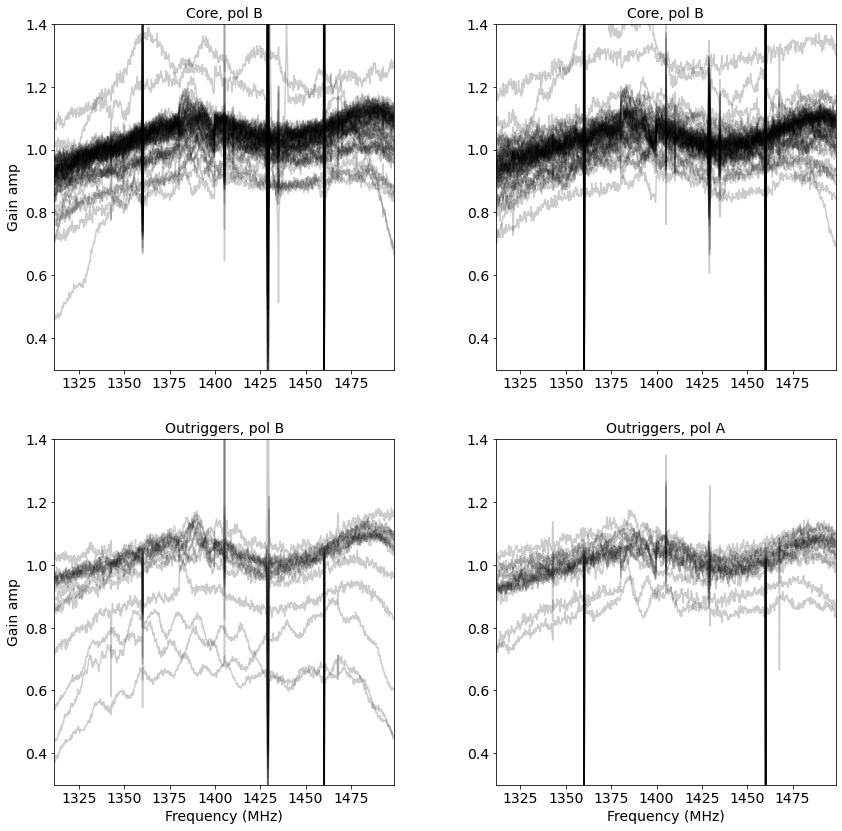

In [21]:
# quality of bandpass solution
trigname = '230501aaae'
from dsacalib.ms_io import read_caltable
bandpass = f"/media/ubuntu/data/localization_processing/{trigname}/{trigname}.B0"
bpvals,bptimes,bpflags,bpa1,bpa2 = read_caltable(bandpass,cparam=True)
# bpvals has shape (117, 1, 1, 768, 2)

# plot core and outrigger amplitudes
freqs = 1530.-1024*250./8192.-np.arange(768)*250./1024.

plt.figure(figsize=(14,14))
plt.subplots_adjust(wspace=0.3,hspace=0.2)

plt.subplot(221)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.ylabel("Gain amp",fontsize=14)
plt.xlim(np.min(freqs),np.max(freqs))
plt.ylim(0.3,1.4)
noants = []
for ant in np.arange(51):
    if ant not in [20,21,22]:
        plt.plot(freqs,np.abs(bpvals[ant,0,0,:,0]),'k-',alpha=0.2)
        #plt.text(1500.,np.abs(bpvals[ant,0,0,:,0])[0],f"{ant+1}",fontsize=11)
        if np.mean(np.abs(bpvals[ant,0,0,:,0]))==1.:
            noants.append(ant+1)
if len(noants)>0:
    plt.title(f"Core, pol B (missing {noants})",fontsize=14)
else:
    plt.title(f"Core, pol B",fontsize=14)
    
plt.subplot(222)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlim(np.min(freqs),np.max(freqs))
plt.ylim(0.3,1.4)
noants = []
for ant in np.arange(51):
    if ant not in [20,21,22]:
        plt.plot(freqs,np.abs(bpvals[ant,0,0,:,1]),'k-',alpha=0.2)
        #plt.text(1500.,np.abs(bpvals[ant,0,0,:,1])[0],f"{ant+1}",fontsize=11)
        if np.mean(np.abs(bpvals[ant,0,0,:,1]))==1.:
            noants.append(ant+1)
if len(noants)>0:
    plt.title(f"Core, pol A (missing {noants})",fontsize=14)
else:
    plt.title(f"Core, pol B",fontsize=14)
    
plt.subplot(223)
plt.ylabel("Gain amp",fontsize=14)
plt.xlabel("Frequency (MHz)",fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlim(np.min(freqs),np.max(freqs))
plt.ylim(0.3,1.4)
noants = []
for ant in np.arange(15)+101:
    plt.plot(freqs,np.abs(bpvals[ant,0,0,:,0]),'k-',alpha=0.2)
    #plt.text(1500.,np.abs(bpvals[ant,0,0,:,0])[0],f"{ant+1}",fontsize=11)
    if np.mean(np.abs(bpvals[ant,0,0,:,0]))==1.:
        noants.append(ant+1)
if len(noants)>0:
    plt.title(f"Outriggers, pol B (missing {noants})",fontsize=14)
else:
    plt.title(f"Outriggers, pol B",fontsize=14)
    
plt.subplot(224)
plt.title("Outriggers, pol A",fontsize=14)
plt.xlabel("Frequency (MHz)",fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlim(np.min(freqs),np.max(freqs))
plt.ylim(0.3,1.4)
noants = []
for ant in np.arange(15)+101:
    plt.plot(freqs,np.abs(bpvals[ant,0,0,:,1]),'k-',alpha=0.2)
    #plt.text(1500.,np.abs(bpvals[ant,0,0,:,1])[0],f"{ant+1}",fontsize=11)
    if np.mean(np.abs(bpvals[ant,0,0,:,1]))==1.:
        noants.append(ant+1)
if len(noants)>0:
    plt.title(f"Outriggers, pol A (missing {noants})",fontsize=14)
else:
    plt.title(f"Outriggers, pol A",fontsize=14)


In [4]:
# to fit a source position

def fit_src(image,ira,idec,plot=True,nside=100,method='gaus',myvmin=-0.001,myvmax=0.1):
    
    
    nont = int(nside/2)
    mydata = image[idec-nont:idec+nont,ira-nont:ira+nont]
    
    if idec-nont<0:
        return None
    if idec+nont>=image.shape[0]:
        return None
    if ira-nont<0:
        return None
    if ira+nont>=image.shape[0]:
        return None
    
    if not mydata[nont,nont] > 0.:
        return None
    
    
    if method=='gaus':
    
        gaus = models.Gaussian2D(amplitude=0.03,
                                 x_mean=0.,
                                 y_mean=0.,
                                 x_stddev=3.0,
                                 y_stddev=3.0,
                                 theta=np.pi/2.)
    
        y, x = np.mgrid[:nside, :nside]
        y = y.astype(np.float64)
        x = x.astype(np.float64)
        y -= nside/2.+0.5
        x -= nside/2.+0.5
        fit = fitting.LevMarLSQFitter()
        p = fit(gaus, x, y, mydata)
    
        print(p.amplitude.value,p.x_mean.value,p.y_mean.value)
    
        if plot:
            plt.figure(figsize=(10,5))
        
            plt.subplot(1,2,1)
            plt.imshow(mydata,vmin=-0.001,vmax=0.1,origin='lower')
            plt.title('Data')
        
            plt.subplot(1,2,2)
            plt.imshow(mydata-p(x,y),vmin=-0.001,vmax=0.1,origin='lower')
            plt.title('Residual')
        
            plt.show()
        
        return p.amplitude.value,p.y_mean.value,p.x_mean.value
    
    if method=='interp':
        
        x = np.arange(nside)-(nside/2.+0.5)
        y = np.arange(nside)-(nside/2.+0.5)
        p = rbs(x,y,mydata)
        
        manyx = np.linspace(np.min(x),np.max(x),nside*20)
        manyy = np.linspace(np.min(y),np.max(y),nside*20)
        
        interps = p(manyx,manyy)
        wrs = np.where(interps==np.max(interps))
        
        x_mean = manyx[wrs[0]]
        y_mean = manyy[wrs[1]]
        amp = np.max(interps)
                
        if plot:
            plt.figure(figsize=(5,5))
        
            plt.imshow(mydata,origin='lower',vmin=myvmin,vmax=myvmax,extent=[np.min(x),np.max(x),np.min(y),np.max(y)])
            plt.plot([y_mean],[x_mean],'kx')
            plt.title('Data')
        
            plt.show()
            
        return(amp,x_mean,y_mean)
        
        
        

In [5]:
# to fit in RA and DEC
from scipy.optimize import minimize

def line_model(pars, x):

    return pars[0] * np.array(x) + pars[1]

class StraightLineModel(object):
    def __init__(self, x, y, y_err):
        """
        We store the data as attributes of the object so we don't have to
        keep passing it in to the methods that compute the probabilities.
        """
        self.x = np.asarray(x)
        self.y = np.asarray(y)
        self.y_err = np.asarray(y_err)

    def ln_likelihood(self, pars):
        """
        We don't need to pass in the data because we can access it from the
        attributes. This is basically the same as the weighted squared
        deviation function, but includes the constant normalizations for the
        Gaussian likelihood.
        """
        N = len(self.y)
        dy = self.y - line_model(pars, self.x)
        ivar = 1 / self.y_err**2  # inverse-variance
        return -0.5 * (
            N * np.log(2 * np.pi)
            + np.sum(2 * np.log(self.y_err))
            + np.sum(dy**2 * ivar)
        )

    def ln_prior(self, pars):
        """
        The prior only depends on the parameters, so we don't need to touch
        the data at all. We're going to implement a flat (uniform) prior
        over the ranges:
            a : [0, 100]
            b : [-50, 50]

        """

        a, b = pars  # unpack parameters
        ln_prior_val = 0.0  # we'll add to this

        if a < 0 or a > 100.0:
            return -np.inf
        else:
            ln_prior_val += np.log(1e-2)  # normalization, log(1/100)

        if b < -50 or b > 50.0:
            return -np.inf
        else:
            ln_prior_val += np.log(1e-2)  # normalization, log(1/100)

        return ln_prior_val

    def ln_posterior(self, pars):
        """
        Up to a normalization constant, the log of the posterior pdf is just
        the sum of the log likelihood plus the log prior.
        """
        lnp = self.ln_prior(pars)
        if np.isinf(
            lnp
        ):  # short-circuit if the prior is infinite (don't bother computing likelihood)
            return lnp

        lnL = self.ln_likelihood(pars)
        lnprob = lnp + lnL

        if np.isnan(lnprob):
            return -np.inf

        return lnprob

    def __call__(self, pars):
        return self.ln_posterior(pars)


class StraightLineIntrinsicScatterModel(StraightLineModel):
    def ln_prior(self, pars):
        """The prior only depends on the parameters"""

        a, b, lnV = pars

        # flat priors on a, b, lnV
        if a < -2 or a > 2 or b < -10.0 or b > 10.0 or lnV < -2.0 or lnV > 2.0:
            return -np.inf

        # this is only valid up to a numerical constant
        return 0.0

    def ln_likelihood(self, pars):
        """The likelihood function evaluation requires a particular set of model parameters and the data"""
        a, b, lnV = pars
        V = np.exp(lnV)

        N = len(self.y)
        dy = self.y - line_model([a, b], self.x)
        ivar = 1 / (
            self.y_err**2 + V
        )  # inverse-variance now includes intrinsic scatter
        return -0.5 * (
            N * np.log(2 * np.pi) - np.sum(np.log(ivar)) + np.sum(dy**2 * ivar)
        )


In [42]:
# main processing
# (1) check field ms
# (2) check full ms
# (3) check VLBI images, and derive loc offset and error
# (4) measure noise from frb image
# (5) image FRB and measure position

trigname = '221027aags'
odir = f'/dataz/dsa110/tmp_loc/{trigname}'

## Check of field ms v NVSS

Flux (mJy): 50.6
Flux (mJy): 225.4
Flux (mJy): 55.2
Flux (mJy): 54.4
Flux (mJy): 65.4
Flux (mJy): 98.9
Flux (mJy): 57.9
Flux (mJy): 162.0
Flux (mJy): 59.1
Flux (mJy): 67.8


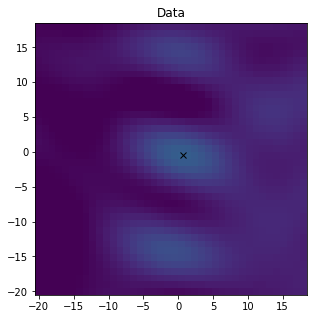

Flux (mJy): 51.6


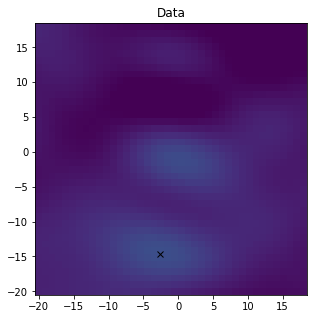

Flux (mJy): 72.0


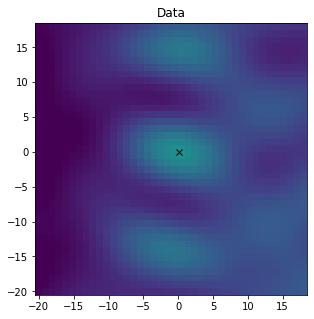

Flux (mJy): 76.6


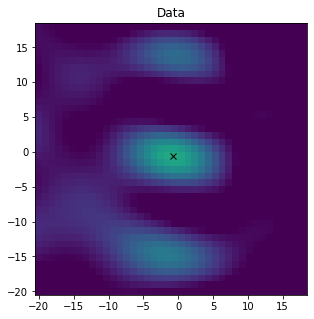

Flux (mJy): 190.8
Flux (mJy): 96.5
Flux (mJy): 602.3


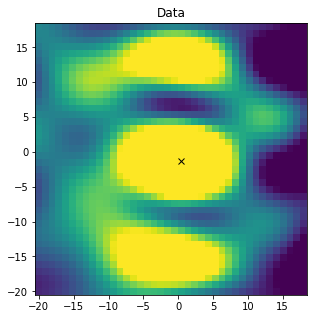

Flux (mJy): 3823.1


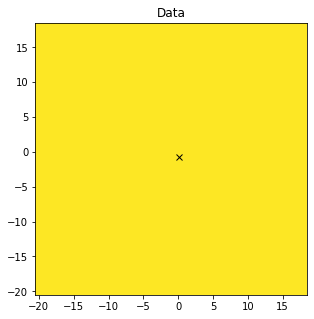

Flux (mJy): 119.7


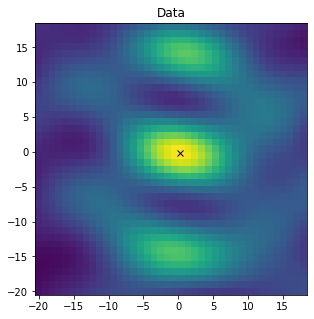

Flux (mJy): 116.3


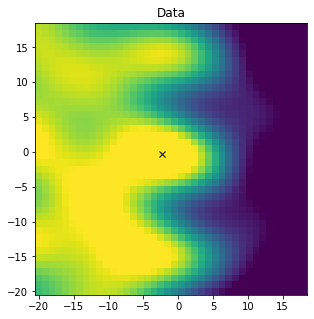

Flux (mJy): 53.3


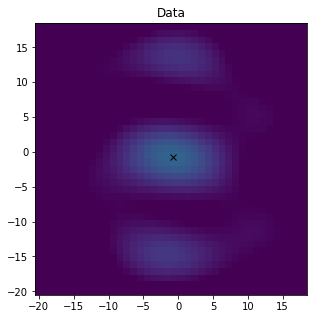

Flux (mJy): 55.2
Flux (mJy): 194.8
Flux (mJy): 53.5


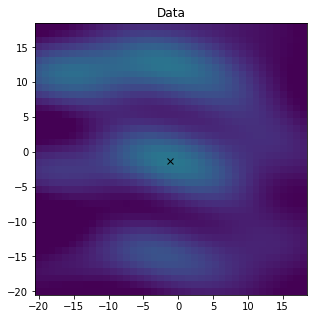

Flux (mJy): 961.9


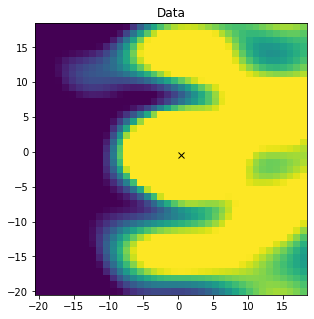

Flux (mJy): 53.7


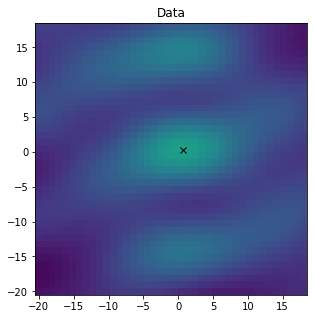

Flux (mJy): 71.5
Flux (mJy): 62.3


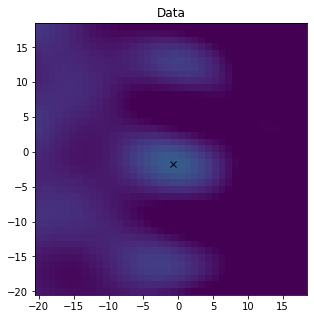

Flux (mJy): 69.3
Flux (mJy): 60.0
Flux (mJy): 264.0


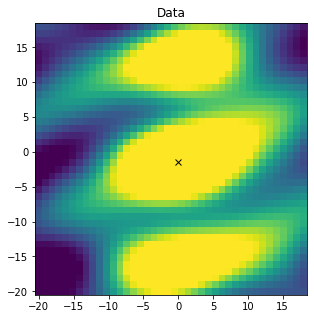

Flux (mJy): 190.8


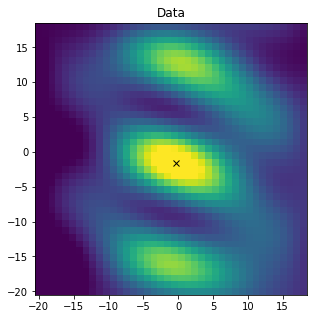

Flux (mJy): 102.5


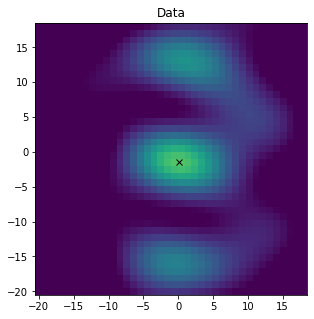

Flux (mJy): 173.3
Flux (mJy): 57.4


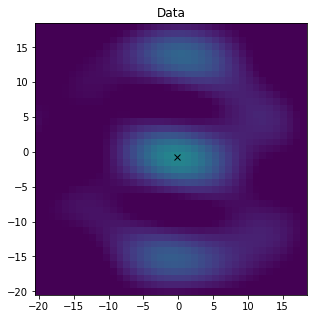

Flux (mJy): 51.1
Flux (mJy): 408.7
Flux (mJy): 296.6


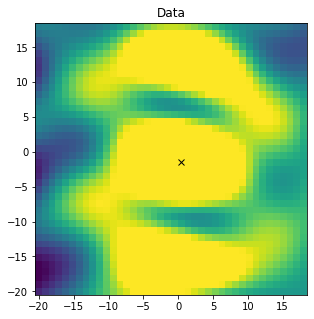

Flux (mJy): 317.8
Flux (mJy): 247.3


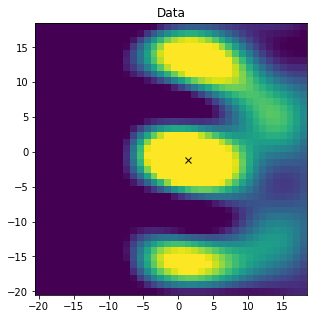

Flux (mJy): 472.5
Flux (mJy): 65.4
Flux (mJy): 278.0


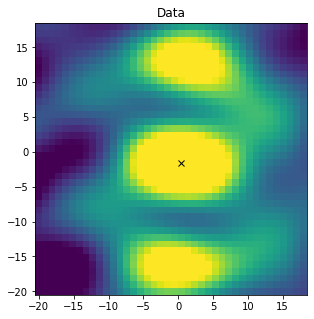

Flux (mJy): 57.4


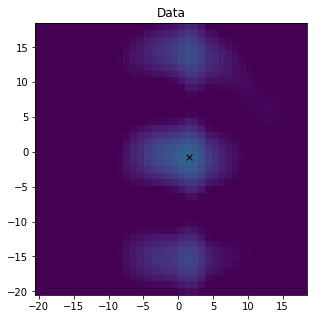

Flux (mJy): 89.4


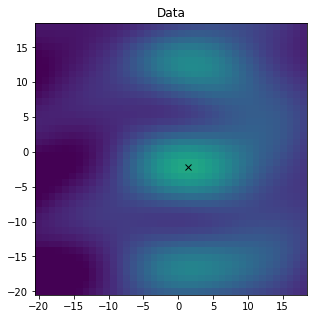

Flux (mJy): 99.8


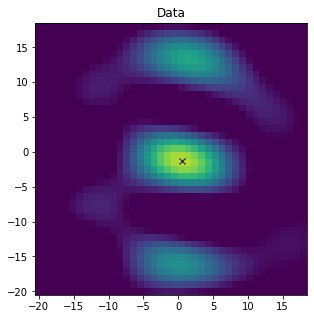

Flux (mJy): 98.1
Flux (mJy): 97.1


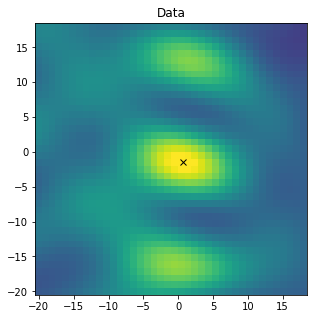

Flux (mJy): 129.3


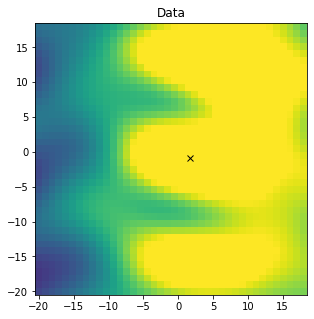

Flux (mJy): 62.2


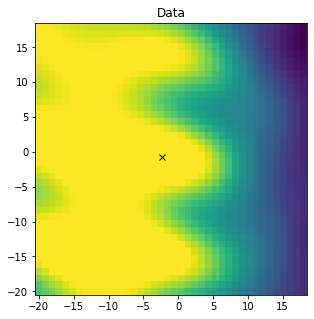

Flux (mJy): 114.1


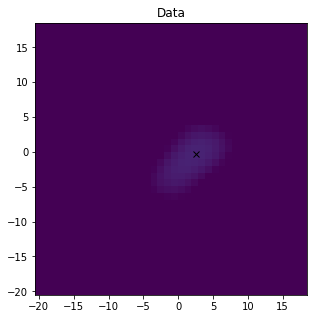

Flux (mJy): 90.6
Flux (mJy): 129.8
Flux (mJy): 60.2
Flux (mJy): 70.6
Flux (mJy): 104.5
Flux (mJy): 54.5
Flux (mJy): 72.4
Flux (mJy): 82.7
Flux (mJy): 119.9
Flux (mJy): 290.2


In [43]:
d = fits.open(f'{odir}/images/fimg-image.fits')
image = d[0].data[0,0,:,:]
w = WCS(d[0].header)
skypos = w.wcs_pix2world(image.shape[0]/2, image.shape[0]/2, 0, 0, 0)
pos = SkyCoord([skypos[0]],[skypos[1]],unit=(u.deg,u.deg))

# NVSS conditions
flux_lt = 50.0
maj_lt = 20.0
rad_lt = 2.5

idx, d2d, d3d = coords.match_to_catalog_sky(pos)
wrs = np.where((flux>flux_lt) & (maj<maj_lt) & (d2d.deg<rad_lt))[0]
ccoords = coords[wrs]
fflux = flux[wrs]
mmaj = maj[wrs]

world_coords = np.zeros((len(ccoords),4))
world_coords[:,0] = ccoords.ra.value
world_coords[:,1] = ccoords.dec.value
world_coords[:,3] = 1.
world_coords[:,2] = 1.405e9
pix_coords = w.wcs_world2pix(world_coords,0)
rapix = np.floor(pix_coords[:,0]).astype('int')
depix = np.floor(pix_coords[:,1]).astype('int')

fit_amp = np.zeros(len(rapix))
fit_ra = np.zeros(len(rapix))
fit_dec = np.zeros(len(rapix))

for i in np.arange(len(rapix)):
    
    print('Flux (mJy):',fflux[i])
    
    pp = fit_src(image,rapix[i],depix[i],nside=40,method='interp')
    
    if pp is not None:
        famp,fx,fy = pp
        fit_amp[i] = famp
        fit_ra[i] = -fy
        fit_dec[i] = fx




MEAN position (RA, DEC): -0.2092289274636782 -1.9002557544757035
UNCERTAINTIES (RA, DEC): 2.0862860060357824 1.162541639557527


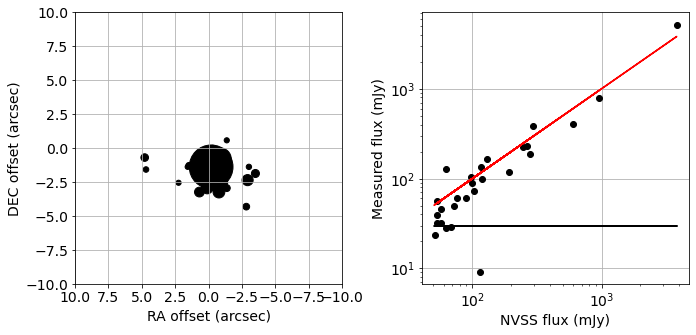

In [44]:
# diagnostic plot

plt.figure(figsize=(11,5.))
plt.subplots_adjust(wspace=0.3)
fluxlt = 0.03

plt.subplot(121)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel("RA offset (arcsec)",fontsize=14)
plt.ylabel("DEC offset (arcsec)",fontsize=14)
scl = 2.
fx = scl*fit_ra[fit_amp>fluxlt]
fy = scl*fit_dec[fit_amp>fluxlt]
fflux2 = fflux[fit_amp>fluxlt]
pixlt = 5.*scl

mn1 = np.mean(fx[np.abs(fx)<pixlt]); mn2 = np.mean(fy[np.abs(fy)<pixlt])

plt.scatter(fx,fy,s=fflux2/2.,color='black')

plt.xlim(pixlt,-pixlt)
plt.ylim(-pixlt,pixlt)
print('MEAN position (RA, DEC):',mn1,mn2)
print('UNCERTAINTIES (RA, DEC):',np.std(fx[np.abs(fx)<pixlt]),np.std(fy[np.abs(fy)<pixlt]))

plt.grid()

plt.subplot(122)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel('NVSS flux (mJy)',fontsize=14)
plt.ylabel('Measured flux (mJy)',fontsize=14)

plt.loglog(fflux,fit_amp*1e3,'ko')
plt.plot(fflux,fflux,'r-')
plt.plot(fflux,np.zeros(len(fflux))+fluxlt*1000.,'k-')
plt.grid()

plt.show()

nvss_raoff = fx
nvss_decoff = fy

## Check brightest sources from full ms

In [10]:
# image 
from casatasks import *
import os

image_full = True

if image_full:
    
    try:
        split(vis=f"{odir}/{trigname}_full.ms",outputvis=f"{odir}/frb_full.ms",datacolumn="DATA")
        applycal(vis=f"{odir}/frb_full.ms",gaintable=[f"{odir}/{trigname}.B0"],interp=['nearest'])
    except:
        print("cannot (re)make frb_full.ms")
    os.system(f"cd {odir}/images; wsclean -weight briggs 0.5 -name full -size 6000 6000 -scale 2asec -minuv-l 200 -niter 100 -auto-threshold 4.0 -theoretic-beam ../frb_full.ms; cd -")
    


2024-04-24 21:43:37	SEVERE	MeasTable::dUTC(Double) (file casacore/measures/Measures/MeasTable.cc, line 4290)	Leap second table TAI_UTC seems out-of-date.
2024-04-24 21:43:37	SEVERE	MeasTable::dUTC(Double) (file casacore/measures/Measures/MeasTable.cc, line 4290)+	Until the table is updated (see the CASA documentation or your system admin),
2024-04-24 21:43:37	SEVERE	MeasTable::dUTC(Double) (file casacore/measures/Measures/MeasTable.cc, line 4290)+	times and coordinates derived from UTC could be wrong by 1s or more.



WSClean version 2.6 (2018-06-11)
This software package is released under the GPL version 3.
Author: André Offringa (offringa@gmail.com).

First measurement set has corrected data: tasks will be applied on the corrected data column.
=== IMAGING TABLE ===
       # Pol Ch JG ²G In Freq(MHz)
| Independent group:
+-+-J- 0  I   0  0  0  0  1311-1499 (768)

Detected 93.1 GB of system memory, usage not limited.
Opening ../frb_full.ms, spw 0 with contiguous MS reader.
Mapping measurement set rows... DONE (0-30240; 29295 rows)
Precalculating weights for Briggs'(0.5) weighting... DONE
 == Constructing PSF ==
Determining min and max w & theoretical beam size... DONE (w=[2.94474e-07:6289.33] lambdas, maxuvw=13005.4 lambda)
Theoretic beam = 15.86''
Minimal inversion size: 1816 x 1816, using optimal: 1920 x 1920
The theoretically suggested number of w-layers (34) is less than the number of availables
cores (40). Changing suggested number of w-layers to 40.
Suggested number of w-layers: 40
Will proce

Flux (mJy): 193.6
Flux (mJy): 263.6
Flux (mJy): 508.5
Flux (mJy): 185.4
Flux (mJy): 190.1
Flux (mJy): 1899.3
Flux (mJy): 386.3


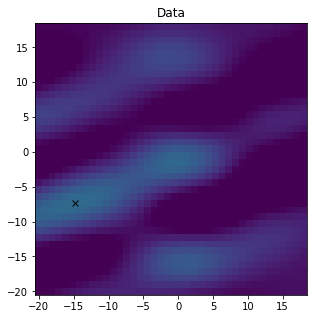

Flux (mJy): 156.6


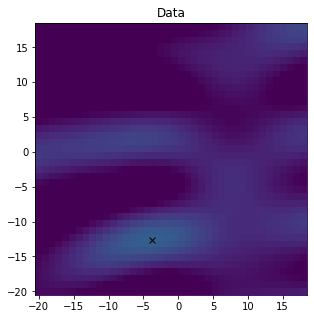

Flux (mJy): 398.3
Flux (mJy): 1554.9


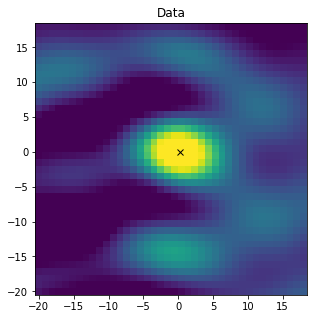

Flux (mJy): 180.6
Flux (mJy): 297.9
Flux (mJy): 158.6
Flux (mJy): 224.8
Flux (mJy): 181.0
Flux (mJy): 751.5


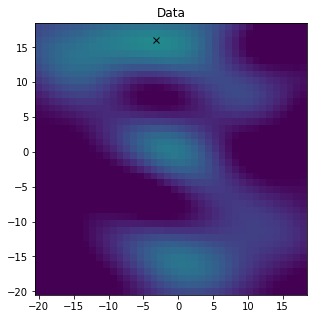

Flux (mJy): 156.8


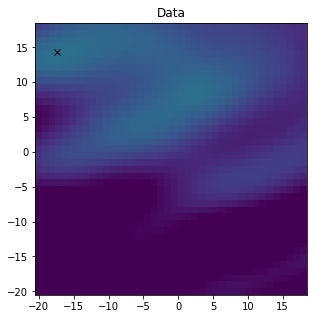

Flux (mJy): 267.6
Flux (mJy): 151.9


In [27]:
# process image

d2 = fits.open(f'{odir}/images/full-image.fits')
image2 = d2[0].data[0,0,:,:]
w2 = WCS(d2[0].header)
skypos2 = w2.wcs_pix2world(image2.shape[0]/2, image2.shape[0]/2, 0, 0, 0)
pos2 = SkyCoord([skypos2[0]],[skypos2[1]],unit=(u.deg,u.deg))

# NVSS conditions
flux_lt = 150.
maj_lt = 30.0
rad_lt = 2.5

idx, d2d, d3d = coords.match_to_catalog_sky(pos2)
wrs = np.where((flux>flux_lt) & (maj<maj_lt) & (d2d.deg<rad_lt))[0]
ccoords = coords[wrs]
fflux2 = flux[wrs]
mmaj = maj[wrs]

world_coords = np.zeros((len(ccoords),4))
world_coords[:,0] = ccoords.ra.value
world_coords[:,1] = ccoords.dec.value
world_coords[:,3] = 1.
world_coords[:,2] = 1.405e9
pix_coords = w2.wcs_world2pix(world_coords,0)
rapix = np.floor(pix_coords[:,0]).astype('int')
depix = np.floor(pix_coords[:,1]).astype('int')

fit_amp2 = np.zeros(len(rapix))
fit_ra2 = np.zeros(len(rapix))
fit_dec2 = np.zeros(len(rapix))

for i in np.arange(len(rapix)):
    
    print('Flux (mJy):',fflux2[i])
    
    pp = fit_src(image2,rapix[i],depix[i],nside=40,method='interp',myvmin=-0.00003,myvmax=0.003)
    
    if pp is not None:
        famp,fx,fy = pp
        fit_amp2[i] = famp
        fit_ra2[i] = -fy
        fit_dec2[i] = fx
    else:
        fit_amp2[i] = -1.
    





NameError: name 'fit_ra2' is not defined

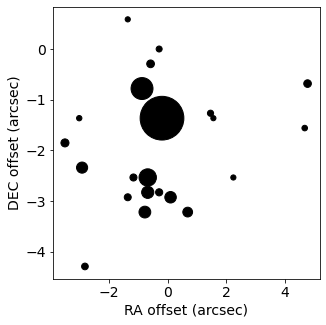

In [45]:
# diagnostic plot

plt.figure(figsize=(11,5))
fluxlt = 0.03
plt.subplots_adjust(wspace=0.3)

plt.subplot(121)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel("RA offset (arcsec)",fontsize=14)
plt.ylabel("DEC offset (arcsec)",fontsize=14)
scl = 2.
fx = scl*fit_ra[fit_amp>fluxlt]
fy = scl*fit_dec[fit_amp>fluxlt]
fflux3 = fflux[fit_amp>fluxlt]
pixlt = 3.*scl

mn1 = np.mean(fx[np.abs(fx)<pixlt]); mn2 = np.mean(fy[np.abs(fy)<pixlt])

plt.scatter(fx,fy,s=fflux3/2.,color='black')

plt.scatter(scl*fit_ra2[fit_amp2>0.],scl*fit_dec2[fit_amp2>0.],s=fflux2[fit_amp2>0.]/3.,color='red')

plt.xlim(pixlt,-pixlt)
plt.ylim(-pixlt,pixlt)
print('NVSS MEAN (RA, DEC; arcsec):',mn1,mn2)
print('UNCERTAINTY (RA, DEC; arcsec):',np.std(fx[np.abs(fx)<pixlt]),np.std(fy[np.abs(fy)<pixlt]))

plt.grid()

plt.subplot(122)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel('NVSS flux (mJy)',fontsize=14)
plt.ylabel('Measured flux (mJy)',fontsize=14)

plt.loglog(fflux,fit_amp*1e3,'ko')

plt.plot(fflux,fflux,'r-')
plt.plot(fflux,np.zeros(len(fflux))+fluxlt*1000.,'k-')
plt.grid()

plt.show()

## Check VLBI images and derive offset

/dataz/dsa110/tmp_loc/221027aags/icrs_image/J0841+7053-dirty.fits


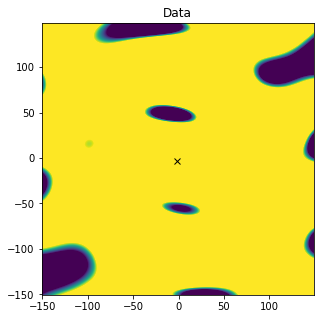

/dataz/dsa110/tmp_loc/221027aags/icrs_image/J0921+7136-dirty.fits


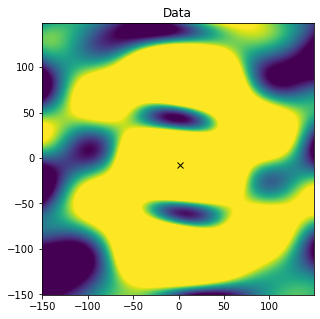

/dataz/dsa110/tmp_loc/221027aags/icrs_image/J1027+7428-dirty.fits
/dataz/dsa110/tmp_loc/221027aags/icrs_image/J0856+7146-dirty.fits


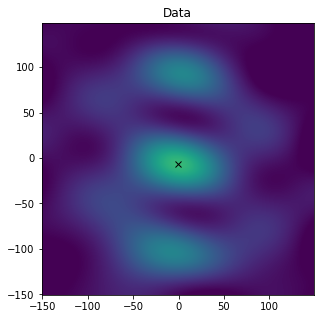

/dataz/dsa110/tmp_loc/221027aags/icrs_image/J0754+7140-dirty.fits


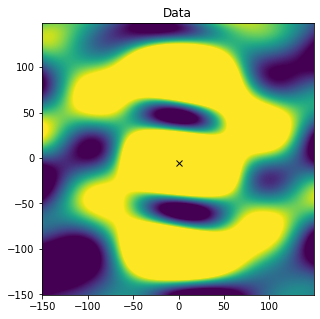

/dataz/dsa110/tmp_loc/221027aags/icrs_image/J0956+7219-dirty.fits
/dataz/dsa110/tmp_loc/221027aags/icrs_image/J0811+7051-dirty.fits


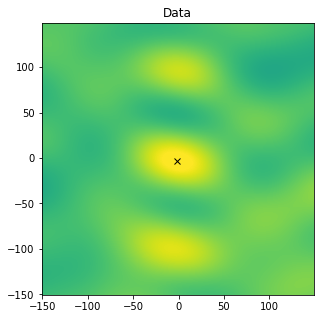

/dataz/dsa110/tmp_loc/221027aags/icrs_image/J0740+7129-dirty.fits


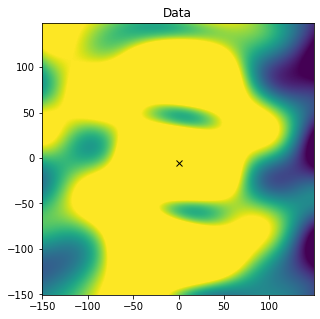

/dataz/dsa110/tmp_loc/221027aags/icrs_image/J0905+7230-dirty.fits


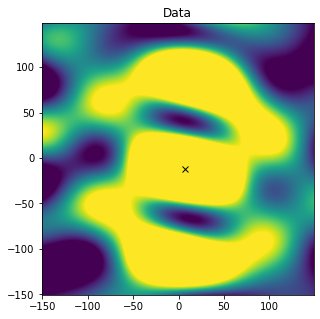

FLAGGING THE ABOVE
/dataz/dsa110/tmp_loc/221027aags/icrs_image/J0750+7217-dirty.fits


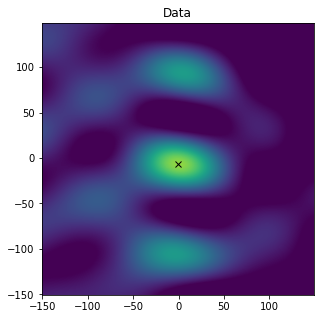

In [49]:
# guess at FRB position from frb image
frbpos = SkyCoord("08h43m29.28s","+72d06m03.4s",unit=(u.hourangle,u.deg))
idict = np.load(odir+"/rfc_idict.npz",allow_pickle=True)['idict'].item()

filenames = []
for i,n in enumerate(idict["jname"]):
    filenames.append(odir+"/icrs_image/"+n+"-dirty.fits")
posses = idict['position']
fluxes = idict['flux']

mypixlt = 10.

# get pixel coords

famp = np.zeros(len(posses))
fra = np.zeros(len(posses))
fdec = np.zeros(len(posses))
myx = np.zeros(len(posses))
myflux = np.zeros(len(posses))

for i,f in enumerate(filenames):
    
    try:
    
        print(f)
        d = fits.open(f)
        image = d[0].data[0,0,:,:]
        w = WCS(d[0].header)
    
        world_coords = np.zeros((1,4))
        world_coords[0,0] = posses[i].ra.value
        world_coords[0,1] = posses[i].dec.value
        world_coords[0,3] = 1.
        world_coords[0,2] = 1.405e9
        pix_coords = w.wcs_world2pix(world_coords,0)
        rapix = np.floor(pix_coords[:,0]).astype('int')[0]
        depix = np.floor(pix_coords[:,1]).astype('int')[0]

        pp = fit_src(image,rapix,depix,nside=300,method='interp')
        
        if pp is not None:
            flamp,fx,fy = pp
            famp[i] = flamp
            fra[i] = -fy[0]
            fdec[i] = fx[0]
            myx[i] = posses[i].ra.deg
            myflux[i] = fluxes[i]
            
        if np.sqrt(fx[0]**2.+fy[0]**2.)>mypixlt:
            famp[i] = np.nan
            fra[i] = np.nan
            fdec[i] = np.nan
            myx[i] = np.nan
            myflux[i] = np.nan
            print("FLAGGING THE ABOVE")
                
    except:
        famp[i] = np.nan
        fra[i] = np.nan
        fdec[i] = np.nan
        myx[i] = np.nan
        myflux[i] = np.nan
        


In [50]:
# clean up data, and fit

scl = 0.5
fluxlt = 0.01
fx = scl*fra[famp>fluxlt]
fy = scl*fdec[famp>fluxlt]
mmyx = myx[famp>fluxlt]
mmyflux = myflux[famp>fluxlt]
frbx = frbpos.ra.deg

ylt = 10.
fx[np.abs(fx-np.median(fx))>ylt] = np.nan
fy[np.abs(fy-np.median(fy))>ylt] = np.nan
fx[np.isnan(fy)] = np.nan
fy[np.isnan(fx)] = np.nan
mmyx[np.isnan(fy)] = np.nan
mmyflux[np.isnan(fy)] = np.nan

fx = fx[~np.isnan(fx)]
fy = fy[~np.isnan(fy)]
mmyx = mmyx[~np.isnan(mmyx)]
mmyflux = mmyflux[~np.isnan(mmyflux)]
mmyerr = 0.45*25./(1000.*mmyflux)

scatter_model_x = StraightLineIntrinsicScatterModel(mmyx,fx,mmyerr)
x0 = [0.01, 0., 0.]  # starting guess for the optimizer
result_ml_scatter_x = minimize(
    lambda *args: -scatter_model_x.ln_likelihood(*args), x0=x0, method="BFGS"
)
print(result_ml_scatter_x)

scatter_model_y = StraightLineIntrinsicScatterModel(mmyx,fy,mmyerr)
x0 = [0.01, 0., 0.]  # starting guess for the optimizer
result_ml_scatter_y = minimize(
    lambda *args: -scatter_model_y.ln_likelihood(*args), x0=x0, method="BFGS"
)
print(result_ml_scatter_y)

      fun: 4.746977394067508
 hess_inv: array([[ 4.24975799e-04, -5.35294059e-02,  1.78089275e-04],
       [-5.35294059e-02,  6.77531861e+00, -2.25632802e-02],
       [ 1.78089275e-04, -2.25632802e-02,  3.07234641e-01]])
      jac: array([-6.16014004e-04, -6.73532486e-06, -3.14116478e-05])
  message: 'Desired error not necessarily achieved due to precision loss.'
     nfev: 235
      nit: 12
     njev: 56
   status: 2
  success: False
        x: array([-0.00919602,  1.24775257, -1.52000208])
      fun: 8.203778816651667
 hess_inv: array([[ 5.87066024e-05, -6.15437649e-03,  6.15432713e-03],
       [-6.15437649e-03,  7.16410464e-01, -7.16404346e-01],
       [ 6.15432713e-03, -7.16404346e-01,  7.16403625e-01]])
      jac: array([1.01804733e-04, 7.15255737e-07, 1.43051147e-06])
  message: 'Desired error not necessarily achieved due to precision loss.'
     nfev: 96
      nit: 15
     njev: 24
   status: 2
  success: False
        x: array([-0.03448381,  1.58009613, -0.51077585])


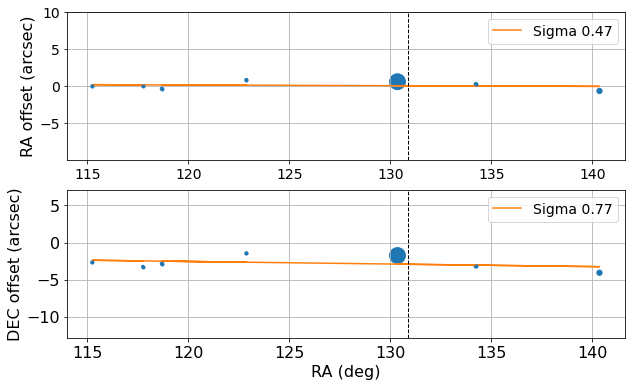

RA offset (arcsec): 0.04425073177699557
DEC offset (arcsec): -2.932869441652132


In [51]:
plt.figure(figsize=(10,6))
plt.subplot(211)
plt.yticks(fontsize=14)
plt.xticks(fontsize=14)

plt.ylabel("RA offset (arcsec)",fontsize=16)
plt.scatter(mmyx,fx,s=mmyflux/0.01)
plt.errorbar(mmyx,fx,fmt='.',yerr=mmyerr)
plt.plot(mmyx,line_model(result_ml_scatter_x.x[:2], mmyx),'-',label=f'Sigma {np.sqrt(np.exp(result_ml_scatter_x.x[2])):.2f}')

plt.ylim(np.median(fx)-ylt,np.median(fx)+ylt)
plt.plot([frbx,frbx],[np.median(fx)-ylt,np.median(fx)+ylt],'k--',lw=1.)
plt.legend(fontsize=14)
plt.grid()

plt.subplot(212)
plt.xlabel("RA (deg)",fontsize=16)
plt.yticks(fontsize=16)
plt.xticks(fontsize=16)

plt.ylabel("DEC offset (arcsec)",fontsize=16)
plt.ylim(np.median(fy)-ylt,np.median(fy)+ylt)
plt.scatter(mmyx,fy,s=mmyflux/0.01)
plt.errorbar(mmyx,fy,fmt='.',yerr=mmyerr)
plt.plot(mmyx,line_model(result_ml_scatter_y.x[:2], mmyx),'-',label=f'Sigma {np.sqrt(np.exp(result_ml_scatter_y.x[2])):.2f}')
plt.plot([frbx,frbx],[np.median(fy)-ylt,np.median(fy)+ylt],'k--',lw=1.)
plt.legend(fontsize=14)
plt.grid()

plt.show()

print("RA offset (arcsec):",line_model(result_ml_scatter_x.x[:2], frbx))
print("DEC offset (arcsec):",line_model(result_ml_scatter_y.x[:2], frbx))

#myoffset_ra = u.arcsec*line_model(result_ml_scatter_x.x[:2], frbx)
myoffset_ra = u.arcsec*0.
myoffset_dec = u.arcsec*line_model(result_ml_scatter_y.x[:2], frbx)


vlbi_raoff =  fx - line_model(result_ml_scatter_x.x[:2], mmyx)
vlbi_decoff = fy - line_model(result_ml_scatter_y.x[:2], mmyx)
nvss_raoff -= myoffset_ra.value 
nvss_decoff -= myoffset_dec.value

## image and localize FRB

In [52]:
do_tclean = True
import os
from casatasks import *

if do_tclean:
    
    os.system(f"rm -rf {odir}/images/closeup*")
    tclean(vis=f"{odir}/frb_bp.ms",imagename=f"{odir}/images/closeup_zero",uvrange=">0.2klambda",
           imsize=[1000,1000],cell=['0.3arcsec','0.3arcsec'],weighting='briggs',robust=0.5,
           niter=0,pblimit=0.0,interactive=False,phasecenter=f"J2000 {frbpos.to_string('hmsdms')}")
    tclean(vis=f"{odir}/frb_bp.ms",imagename=f"{odir}/images/closeup",uvrange=">0.2klambda",
           imsize=[1000,1000],cell=['0.3arcsec','0.3arcsec'],weighting='briggs',robust=0.5,
           niter=30,pblimit=0.0,interactive=False,phasecenter=f"J2000 {frbpos.to_string('hmsdms')}")
    exportfits(imagename=f"{odir}/images/closeup_zero.image",fitsimage=f"{odir}/images/closeup.fits")
    exportfits(imagename=f"{odir}/images/closeup_zero.psf",fitsimage=f"{odir}/images/closeup_psf.fits")
    exportfits(imagename=f"{odir}/images/closeup.image",fitsimage=f"{odir}/images/closeup_clean.fits")
    

2024-04-24 23:54:55	WARN	tclean::::casa	Warning! Non-zero values at the edge of the .pb image can cause unexpected aliasing effects! (found value 0.9212637543678284 at index [996, 0, 0, 0])
2024-04-24 23:54:56	WARN	task_tclean::SIImageStore::restore (file src/code/synthesis/ImagerObjects/SIImageStore.cc, line 2247)	Restoring with an empty model image. Only residuals will be processed to form the output restored image.
2024-04-24 23:54:58	WARN	tclean::::casa	Warning! Non-zero values at the edge of the .pb image can cause unexpected aliasing effects! (found value 0.9212637543678284 at index [996, 0, 0, 0])


Set OBSGEO-B to    -0.986523 from OBSGEO-[XYZ].
Set OBSGEO-H to -6377200.288 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


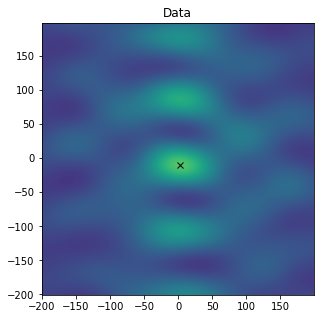

Corrected FRB position: 08h43m29.23365796s +72d06m03.49640863s
Amp: (Jy) 0.06462453433512719


In [53]:
# process image

scl = 0.3
d3 = fits.open(f'{odir}/images/closeup.fits')
image3 = d3[0].data[0,0,:,:]
w3 = WCS(d3[0].header)

world_coords = np.zeros((1,4))
world_coords[:,0] = frbpos.ra.value
world_coords[:,1] = frbpos.dec.value
world_coords[:,3] = 1.
world_coords[:,2] = 1.405e9
pix_coords = w3.wcs_world2pix(world_coords,0)
rapix = np.floor(pix_coords[:,0]).astype('int')
depix = np.floor(pix_coords[:,1]).astype('int')

for i in np.arange(1):
        
    famp,myfdec,myfra = fit_src(image3,rapix[i],depix[i],nside=400,method='interp',myvmin=-0.03,myvmax=0.1)
    fra=-scl*myfra
    fdec = scl*myfdec

    new_ra = frbpos.ra + fra*u.arcsec
    new_dec = frbpos.dec + fdec*u.arcsec
    
new_frbpos = SkyCoord(new_ra-myoffset_ra,new_dec-myoffset_dec)
print("Corrected FRB position:",new_frbpos[0].to_string('hmsdms'))
print("Amp: (Jy)",famp)    




Text(0.07, 0.5, 'DEC offset (arcsec)')

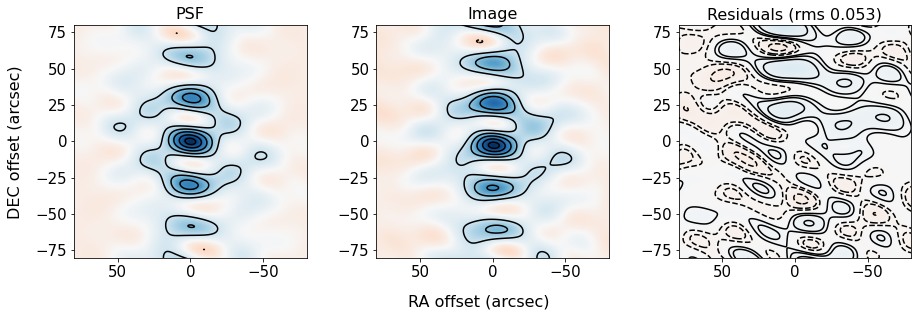

In [54]:
# plot image, psf, and residuals
fig = plt.figure(figsize=(15,6))
plt.subplots_adjust(wspace=0.3)

dima = fits.open(f'{odir}/images/closeup.fits')
dimg = dima[0].data[0,0,:,:]
dima = fits.open(f'{odir}/images/closeup_psf.fits')
dpsf = dima[0].data[0,0,:,:]

from scipy.ndimage import shift
shift_dpsf = shift(dpsf,[myfdec,myfra])
dresid = dimg-shift_dpsf*famp

x = np.arange(500.*0.3,-500.*0.3,-0.3)
y = np.arange(-500.*0.3,500.*0.3,0.3)
xx,yy = np.meshgrid(x, y)
extent = [500.*0.3,-500.*0.3,-500.*0.3,500.*0.3]
levs = [-0.4,-0.2,0.2,0.4,0.6,0.8,0.95]
levs2 = [-0.1,-0.05,-0.025,0.025,0.05,0.1]
lt = 80.

ax = fig.add_subplot(1,3,1)
ax.tick_params(axis='both', which='major', labelsize=15)
ax.set_aspect('equal')
plt.imshow(dpsf,vmin=-1.,vmax=1.,extent=extent,cmap='RdBu',origin='lower')
cs = ax.contour(xx,yy,dpsf,levels=levs,colors='k')
plt.xlim(lt, -lt)
plt.ylim(-lt, lt)
plt.title('PSF',fontsize=16)

ax = fig.add_subplot(1,3,2)
ax.tick_params(axis='both', which='major', labelsize=15)
ax.set_aspect('equal')
plt.imshow(dimg/famp,vmin=-1.,vmax=1.,extent=extent,cmap='RdBu',origin='lower')
cs = ax.contour(xx,yy,dimg/famp,levels=levs,colors='k')
plt.xlim(lt, -lt)
plt.ylim(-lt, lt)
plt.title('Image',fontsize=16)

ax = fig.add_subplot(1,3,3)
ax.tick_params(axis='both', which='major', labelsize=15)
ax.set_aspect('equal')
plt.imshow(dresid,vmin=-0.1,vmax=0.1,extent=extent,cmap='RdBu',origin='lower')
cs = ax.contour(xx,yy,dresid/famp,levels=levs2,colors='k')
plt.xlim(lt, -lt)
plt.ylim(-lt, lt)
plt.title(f'Residuals (rms {np.std(dresid/famp):.3f})',fontsize=16)

fig.text(0.5, 0.13, 'RA offset (arcsec)', ha='center', va='center', fontsize=16)
fig.text(0.07, 0.5, 'DEC offset (arcsec)', ha='center', va='center', rotation='vertical', fontsize=16)





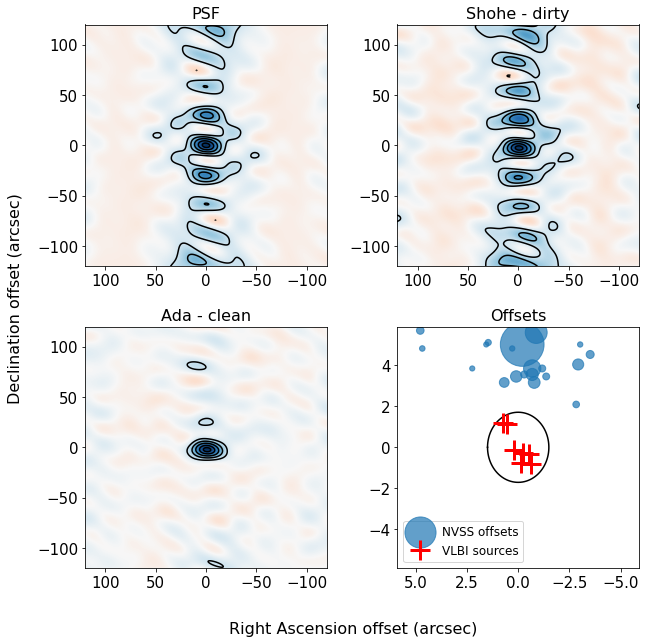

In [55]:
# publication plot

dima = fits.open(f'{odir}/images/closeup_clean.fits')
dclean = dima[0].data[0,0,:,:]

fig = plt.figure(figsize=(10,10))
plt.subplots_adjust(wspace=0.27,hspace=0.25)

x = np.arange(500.*0.3,-500.*0.3,-0.3)
y = np.arange(-500.*0.3,500.*0.3,0.3)
xx,yy = np.meshgrid(x, y)
extent = [500.*0.3,-500.*0.3,-500.*0.3,500.*0.3]
levs = [-0.4,-0.2,0.2,0.4,0.6,0.8,0.95]
lt = 120.

ax = fig.add_subplot(2,2,1)
ax.tick_params(axis='both', which='major', labelsize=15)
ax.set_aspect('equal')
plt.imshow(dpsf,vmin=-1.,vmax=1.,extent=extent,cmap='RdBu',origin='lower')
cs = ax.contour(xx,yy,dpsf,levels=levs,colors='k')
#ax.clabel(cs, inline=1, fontsize=10.)
plt.xlim(lt, -lt)
plt.ylim(-lt, lt)
plt.title('PSF',fontsize=16)

ax = fig.add_subplot(2,2,2)
ax.tick_params(axis='both', which='major', labelsize=15)
ax.set_aspect('equal')
plt.imshow(dimg/np.max(dimg),vmin=-1.,vmax=1.,extent=extent,cmap='RdBu',origin='lower')
cs = ax.contour(xx,yy,dimg/np.max(dimg),levels=levs,colors='k')
#ax.clabel(cs, inline=1, fontsize=10.)
plt.xlim(lt, -lt)
plt.ylim(-lt, lt)
plt.title('Shohe - dirty',fontsize=16)

ax = fig.add_subplot(2,2,3)
ax.tick_params(axis='both', which='major', labelsize=15)
ax.set_aspect('equal')
plt.imshow(dclean/np.max(dclean),vmin=-1.,vmax=1.,extent=extent,cmap='RdBu',origin='lower')
cs = ax.contour(xx,yy,dclean/np.max(dclean),levels=levs,colors='k')
#ax.clabel(cs, inline=1, fontsize=10.)
plt.xlim(lt, -lt)
plt.ylim(-lt, lt)
plt.title('Ada - clean',fontsize=16)

ax = fig.add_subplot(2,2,4)

lt = 5.9

uu=0.     #x-position of the center
v=0.    #y-position of the center
a=0.7*2.14    #radius on the x-axis
b=0.8*2.14   #radius on the y-axis
t = np.linspace(0, 2*np.pi, 100)
x_el = uu+a*np.cos(t)
y_el = v+b*np.sin(t)

ax.tick_params(axis='both', which='major', labelsize=15)
ax.set_aspect('equal')
plt.plot(x_el,y_el,color='black')
plt.scatter(nvss_raoff,nvss_decoff,s=fflux3/2.,alpha=0.7,label='NVSS offsets')
plt.plot(vlbi_raoff,vlbi_decoff,'+',markersize=20,mew=3.,color='red',label='VLBI sources')
plt.legend(fontsize=12,ncol=1,loc='lower left')
plt.xlim(lt,-lt)
plt.ylim(-lt,lt)
plt.title('Offsets',fontsize=16)


fig.text(0.5, 0.04, 'Right Ascension offset (arcsec)', ha='center', va='center', fontsize=16)
fig.text(0.03, 0.5, 'Declination offset (arcsec)', ha='center', va='center', rotation='vertical', fontsize=16)

plt.savefig('localizations.pdf',bbox_inches='tight')

plt.show()

### To finish up, calculate the error by adding the sigmas in quadrature to the statistical error on a 26.9 x 15.6 '' beam, scaled by the SNR in the frb image. 

Text(-13.0, -16.0, "10''")

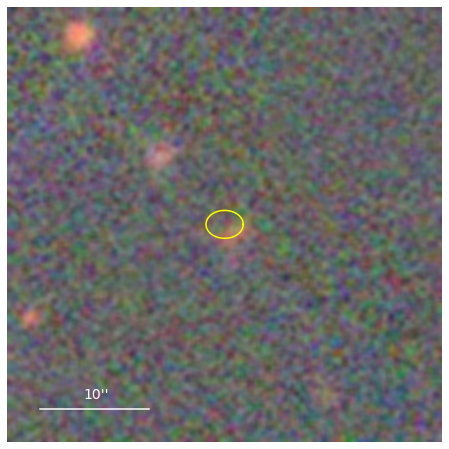

In [41]:
import requests
from PIL import Image
from io import BytesIO
from astropy.table import Table
from scipy.ndimage import zoom
import cv2

def getimages(ra,dec,filters="grizy"):
    
    """Query ps1filenames.py service to get a list of images
    
    ra, dec = position in degrees
    size = image size in pixels (0.25 arcsec/pixel)
    filters = string with filters to include
    Returns a table with the results
    """
    
    service = "https://ps1images.stsci.edu/cgi-bin/ps1filenames.py"
    url = f"{service}?ra={ra}&dec={dec}&filters={filters}"
    table = Table.read(url, format='ascii')
    return table

def geturl(ra, dec, size=240, output_size=None, filters="grizy", format="jpg", color=False):
    
    """Get URL for images in the table
    
    ra, dec = position in degrees
    size = extracted image size in pixels (0.25 arcsec/pixel)
    output_size = output (display) image size in pixels (default = size).
                  output_size has no effect for fits format images.
    filters = string with filters to include
    format = data format (options are "jpg", "png" or "fits")
    color = if True, creates a color image (only for jpg or png format).
            Default is return a list of URLs for single-filter grayscale images.
    Returns a string with the URL
    """
    
    if color and format == "fits":
        raise ValueError("color images are available only for jpg or png formats")
    if format not in ("jpg","png","fits"):
        raise ValueError("format must be one of jpg, png, fits")
    table = getimages(ra,dec,filters=filters)
    url = (f"https://ps1images.stsci.edu/cgi-bin/fitscut.cgi?"
           f"ra={ra}&dec={dec}&size={size}&format={format}")
    if output_size:
        url = url + "&output_size={}".format(output_size)
    # sort filters from red to blue
    flist = ["yzirg".find(x) for x in table['filter']]
    table = table[np.argsort(flist)]
    if color:
        if len(table) > 3:
            # pick 3 filters
            table = table[[0,len(table)//2,len(table)-1]]
        for i, param in enumerate(["red","green","blue"]):
            url = url + "&{}={}".format(param,table['filename'][i])
    else:
        urlbase = url + "&red="
        url = []
        for filename in table['filename']:
            url.append(urlbase+filename)
    return url


def getcolorim(ra, dec, size=240, output_size=None, filters="grizy", format="jpg"):
    
    """Get color image at a sky position
    
    ra, dec = position in degrees
    size = extracted image size in pixels (0.25 arcsec/pixel)
    output_size = output (display) image size in pixels (default = size).
                  output_size has no effect for fits format images.
    filters = string with filters to include
    format = data format (options are "jpg", "png")
    Returns the image
    """
    
    if format not in ("jpg","png"):
        raise ValueError("format must be jpg or png")
    url = geturl(ra,dec,size=size,filters=filters,output_size=output_size,format=format,color=True)
    r = requests.get(url)
    with open('tmp.jpg','wb') as fl:
        fl.write(r.content)
    fl.close()
    im = cv2.imread('tmp.jpg')
    img_RGB = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
    return img_RGB

def adjust_gamma(image, gamma=1.0):

    invGamma = 1.0 / gamma
    table = np.array([((i / 255.0) ** invGamma) * 255
        for i in np.arange(0, 256)]).astype("uint8")
    return cv2.LUT(image, table)


myra = new_frbpos[0].ra.deg
mydec = new_frbpos[0].dec.deg
inv_gamma = 1.
re_gamma = 1.
size=160
resize_factor=4

cim = getcolorim(myra,mydec,size=size,filters="gri")
cim = adjust_gamma(cim,inv_gamma)
#img_yuv = cv2.cvtColor(cim, cv2.COLOR_BGR2YUV)
#img_yuv[:,:,0] = cv2.equalizeHist(img_yuv[:,:,0])
#cim = cv2.cvtColor(img_yuv, cv2.COLOR_YUV2BGR)
#cim = adjust_gamma(cim,re_gamma)
cim_big = cv2.resize(cim,(resize_factor*size,resize_factor*size),interpolation=cv2.INTER_CUBIC)
cim_big = cv2.blur(src=cim_big, ksize=(10, 10))


plt.figure(figsize=(8,8))
plt.xlim(-size*0.25/2.,size*0.25/2.)
plt.ylim(-size*0.25/2.,size*0.25/2.)
plt.axis('off')

plt.imshow(cim_big,origin="upper",extent=[-size*0.25/2.,size*0.25/2.,-size*0.25/2.,size*0.25/2.])
plt.plot(x_el,y_el,color='yellow')

plt.plot([-size*0.25/2.+3.,-size*0.25/2.+13.],[-size*0.25/2.+3.,-size*0.25/2.+3.],'-',color='white')
plt.text(-size*0.25/2.+7.,-size*0.25/2.+4.,r"10''",fontsize=14,color='white')
